<a href="https://colab.research.google.com/github/Hadeel-93/HW-6/blob/main/HW_6_Q1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================================
# HOMEWORK 6 - PROBLEM 1
# Housing Price Prediction using a Fully Connected Neural Network
# Comparison: Neural Network vs Linear Regression vs SVR
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
# ------------------------------------------------------------
# 1. Set random seeds for reproducibility
# ------------------------------------------------------------
np.random.seed(42)
tf.random.set_seed(42)

In [3]:
# ------------------------------------------------------------
# 2. Mount Google Drive and load the Housing dataset
# ------------------------------------------------------------
drive.mount('/content/drive')

file_path = (
    '/content/drive/My Drive/'
    'Introduction to Machine Learning/Housing.csv'
)

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

# The target is price; all remaining columns are input features.
target_column = 'price'

X = df.drop(columns=[target_column]).copy()
y = pd.to_numeric(df[target_column], errors='raise')

print("\nNumber of input features:", X.shape[1])
print("Target variable:", target_column)
print("Missing values in target:", y.isna().sum())
print("Missing values in inputs:", X.isna().sum().sum())

# Handle missing data if any are present.
# Numeric columns use the training median.
# Categorical columns use the training most frequent value.
# These values will be learned using the training data only.

# ------------------------------------------------------------
# 3. Split the data: 80% training pool, 20% testing
# ------------------------------------------------------------
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Reserve part of the 80% training pool for validation.
# Final proportions are approximately 68% train, 12% validation,
# and 20% test. All models use the same training subset.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.15, random_state=42
)

print("\nTraining samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))


Mounted at /content/drive
Dataset shape: (545, 13)

First five rows:
      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  

Number of input features: 12


In [4]:
# ------------------------------------------------------------
# 4. Preprocess all input features
# ------------------------------------------------------------
numeric_features = X_train.select_dtypes(
    include=['number']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=['number']
).columns.tolist()

print("\nNumeric features:", numeric_features)
print("Categorical features:", categorical_features)

def make_preprocessor():
    """Create a preprocessing pipeline fitted only on training data."""

    numeric_pipeline = Pipeline([
        ('imputer', __import__('sklearn.impute',
                               fromlist=['SimpleImputer'])
         .SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ('imputer', __import__('sklearn.impute',
                               fromlist=['SimpleImputer'])
         .SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])

    return ColumnTransformer([
        ('numeric', numeric_pipeline, numeric_features),
        ('categorical', categorical_pipeline, categorical_features)
    ])

preprocessor = make_preprocessor()

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Convert to dense arrays for Keras.
# The Housing dataset is small enough for this operation.
if hasattr(X_train_processed, 'toarray'):
    X_train_processed = X_train_processed.toarray()
    X_val_processed = X_val_processed.toarray()
    X_test_processed = X_test_processed.toarray()

X_train_processed = X_train_processed.astype(np.float32)
X_val_processed = X_val_processed.astype(np.float32)
X_test_processed = X_test_processed.astype(np.float32)

# Standardize the target for more stable neural-network training.
# The target scaler is fitted on the training subset only.
y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(
    np.asarray(y_train).reshape(-1, 1)
).astype(np.float32)

y_val_scaled = y_scaler.transform(
    np.asarray(y_val).reshape(-1, 1)
).astype(np.float32)


Numeric features: ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
Categorical features: ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']


In [5]:
# ------------------------------------------------------------
# 5. Build the fully connected neural network
# ------------------------------------------------------------
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_processed.shape[1],)),

    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),

    # One output neuron for continuous house-price prediction.
    tf.keras.layers.Dense(1, activation='linear')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse'
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,969 (15.50 KB)

 Trainable params: 3,969 (15.50 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# ------------------------------------------------------------
# 6. Train the neural network
# ------------------------------------------------------------
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=25,
    restore_best_weights=True
)

history = model.fit(
    X_train_processed,
    y_train_scaled,
    validation_data=(X_val_processed, y_val_scaled),
    epochs=300,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

print("\nEpochs completed:", len(history.history['loss']))
print("Best validation loss (standardized target):",
      min(history.history['val_loss']))

Epoch 1/300
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 0.9406 - val_loss: 0.5222
Epoch 2/300
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.7160 - val_loss: 0.3691
Epoch 3/300
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.5302 - val_loss: 0.2653
Epoch 4/300
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.3832 - val_loss: 0.2282
Epoch 5/300
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.3296 - val_loss: 0.2457
Epoch 6/300
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.3105 - val_loss: 0.2380
Epoch 7/300
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.2945 - val_loss: 0.2335
Epoch 8/300
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.2840 - val_loss: 0.2345
Epoch 9/300
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.2748 - val_loss: 0.2347
Epoch 10/300
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.2664 - val_loss: 0.2333
Epoch 11/300
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2585 - val_loss: 0.2323
Epoch 12/300
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - 

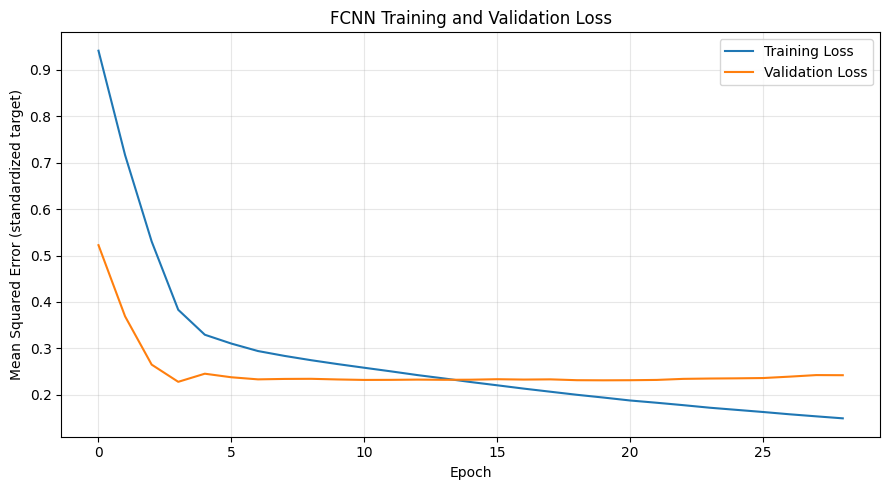

In [7]:
# ------------------------------------------------------------
# 7. Plot training and validation losses
# ------------------------------------------------------------
plt.figure(figsize=(9, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error (standardized target)')
plt.title('FCNN Training and Validation Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [8]:
# ------------------------------------------------------------
# 8. Evaluate the neural network on the test set
# ------------------------------------------------------------
nn_predictions_scaled = model.predict(
    X_test_processed, verbose=0
)

nn_predictions = y_scaler.inverse_transform(
    nn_predictions_scaled
).ravel()

y_test_array = np.asarray(y_test)

def evaluate_regression(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    return {
        'MSE': mse,
        'RMSE': rmse,
        'R2': r2
    }

nn_results = evaluate_regression(
    y_test_array, nn_predictions
)

print("\nNEURAL NETWORK TEST RESULTS")
print(f"MSE:  {nn_results['MSE']:.4f}")
print(f"RMSE: {nn_results['RMSE']:.4f}")
print(f"R²:   {nn_results['R2']:.4f}")


NEURAL NETWORK TEST RESULTS
MSE:  1983816400896.0000
RMSE: 1408480.1741
R²:   0.6075


In [9]:
# ------------------------------------------------------------
# 9. Train Linear Regression and SVR
# ------------------------------------------------------------
# Use the same training, validation, and test split.
# Both models use the same preprocessing approach.

# Linear Regression
linear_model = Pipeline([
    ('preprocessor', make_preprocessor()),
    ('regressor', LinearRegression())
])

linear_model.fit(X_train, y_train)
linear_predictions = linear_model.predict(X_test)

linear_results = evaluate_regression(
    y_test_array, linear_predictions
)

# Support Vector Regression (RBF kernel)
# Standardize the target for SVR training and convert predictions
# back to the original house-price scale.
svr_target_scaler = StandardScaler()

y_train_svr_scaled = svr_target_scaler.fit_transform(
    np.asarray(y_train).reshape(-1, 1)
).ravel()

svr_model = Pipeline([
    ('preprocessor', make_preprocessor()),
    ('regressor', SVR(
        kernel='rbf',
        C=100,
        epsilon=0.1,
        gamma='scale'
    ))
])

svr_model.fit(X_train, y_train_svr_scaled)

svr_predictions_scaled = svr_model.predict(X_test)

svr_predictions = svr_target_scaler.inverse_transform(
    svr_predictions_scaled.reshape(-1, 1)
).ravel()

svr_results = evaluate_regression(
    y_test_array, svr_predictions
)


In [10]:
# ------------------------------------------------------------
# 10. Compare the three models
# ------------------------------------------------------------
results = pd.DataFrame({
    'Model': [
        'Fully Connected Neural Network',
        'Linear Regression',
        'Support Vector Regression (RBF)'
    ],
    'MSE': [
        nn_results['MSE'],
        linear_results['MSE'],
        svr_results['MSE']
    ],
    'RMSE': [
        nn_results['RMSE'],
        linear_results['RMSE'],
        svr_results['RMSE']
    ],
    'R2': [
        nn_results['R2'],
        linear_results['R2'],
        svr_results['R2']
    ]
})

print("\nTEST PERFORMANCE COMPARISON")
print(results.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

# The best model has the lowest MSE and RMSE.
# The best R² is the highest R².
best_by_rmse = results.loc[results['RMSE'].idxmin(), 'Model']
best_by_r2 = results.loc[results['R2'].idxmax(), 'Model']

print("\nBest model by RMSE:", best_by_rmse)
print("Best model by R²:", best_by_r2)



TEST PERFORMANCE COMPARISON
                          Model                MSE         RMSE     R2
 Fully Connected Neural Network 1983816400896.0000 1408480.1741 0.6075
              Linear Regression 1746011556807.9387 1321367.3058 0.6546
Support Vector Regression (RBF) 2815921042340.3433 1678070.6309 0.4429

Best model by RMSE: Linear Regression
Best model by R²: Linear Regression


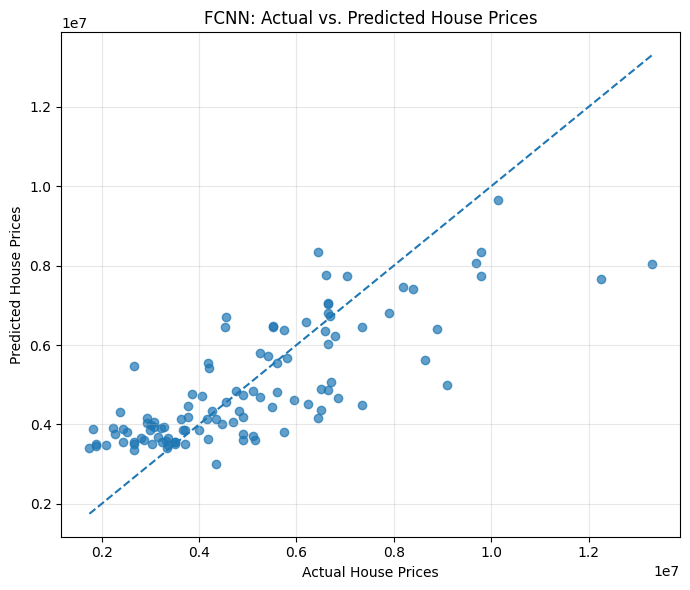

In [11]:
# ------------------------------------------------------------
# 11. Optional: Plot actual versus predicted prices
# ------------------------------------------------------------
plt.figure(figsize=(7, 6))

plt.scatter(y_test_array, nn_predictions, alpha=0.7)

min_price = min(y_test_array.min(), nn_predictions.min())
max_price = max(y_test_array.max(), nn_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle='--'
)

plt.xlabel('Actual House Prices')
plt.ylabel('Predicted House Prices')
plt.title('FCNN: Actual vs. Predicted House Prices')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()